In [88]:
import numpy as np

results = np.load("data_Gauss/results_optim_nphoton_phase.npy", allow_pickle=True).item()

vec_U = results['vec_U']
vec_J = results['vec_J']
vec_n_out = results['vec_target_n_out']
gammas = results['gammas']

print(f"U: {vec_U}")
print(f"Js: {vec_J}")
print(f"n_out contstraint: {vec_n_out}")
print(f"gammas: {gammas}")

U: [0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5]
Js: [0.39269908 0.40872762 0.42475615 0.44078468 0.45681322 0.47284175
 0.48887029 0.50489882 0.52092735 0.53695589 0.55298442 0.56901296
 0.58504149 0.60107002 0.61709856 0.63312709 0.64915562 0.66518416
 0.68121269 0.69724123 0.71326976 0.72929829 0.74532683 0.76135536
 0.7773839  0.79341243 0.80944096 0.8254695  0.84149803 0.85752657
 0.8735551  0.88958363 0.90561217 0.9216407  0.93766924 0.95369777
 0.9697263  0.98575484 1.00178337 1.01781191 1.03384044 1.04986897
 1.06589751 1.08192604 1.09795458 1.11398311 1.13001164 1.14604018
 1.16206871 1.17809725]
n_out contstraint: [0.01, 0.02, 0.05, 0.1, 0.2]
gammas: [0.0, 0.1, 0.5]


In [89]:
import matplotlib.pyplot as plt
from itertools import product

import matplotlib as mpl
mpl.rcParams['text.usetex'] = False
mpl.rcParams['mathtext.fontset'] = 'cm'

U_plot = [0.01, 0.05]
J_plot = vec_J
n_out_plot = [0.01, 0.05, 0.1]
gamma_plot = [0., .5]

num_U, num_J, num_n_out, num_gamma = len(U_plot), len(J_plot), len(n_out_plot), len(gamma_plot)

g2_dat = np.zeros((num_U, num_J, num_n_out, num_gamma))
theta_dat = np.zeros((num_U, num_J, num_n_out, num_gamma))
n_ph_dat = np.zeros((num_U, num_J, num_n_out, num_gamma))

for iU, iJ, i_n_out, ig in product(range(len(U_plot)), range(len(J_plot)), range(len(n_out_plot)), range(len(gamma_plot))):
    
    U, J, n_out, gamma = U_plot[iU], J_plot[iJ], n_out_plot[i_n_out], gamma_plot[ig]
    
    g2_dat[iU,iJ,i_n_out, ig] = results[(U,J,n_out,gamma)]['g2']
    theta_dat[iU,iJ,i_n_out, ig] = results[(U,J,n_out,gamma)]['phase']
    n_ph_dat[iU,iJ,i_n_out, ig] = results[(U,J,n_out,gamma)]['n_photon']



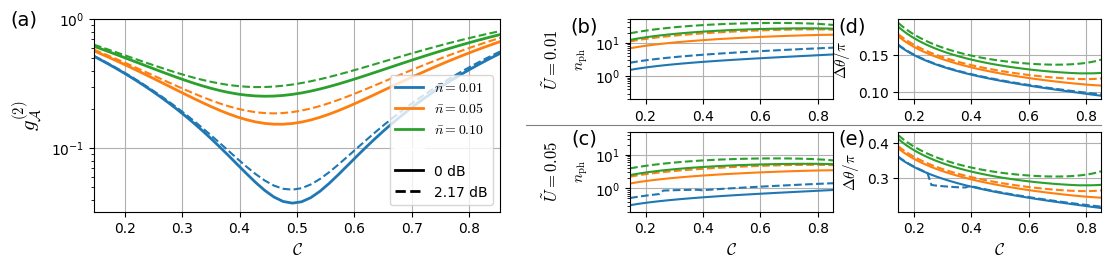

In [146]:
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D

x_axis = np.sin(J_plot) ** 2
colors = [plt.cm.tab10(i) for i in range(10)]

plt.rcParams['mathtext.fontset'] = 'cm'
plt.rcParams['text.usetex'] = False

fig = plt.figure(figsize=(13, 2.5))
gs = GridSpec(2, 4, figure=fig, width_ratios=[2, 0., 1, 1], wspace=0.32, hspace=0.4)

ax_a = fig.add_subplot(gs[:, 0])
ax_b = fig.add_subplot(gs[0, 2])
ax_c = fig.add_subplot(gs[1, 2])
ax_d = fig.add_subplot(gs[0, 3])
ax_e = fig.add_subplot(gs[1, 3])


axes_right = [ax_b, ax_c, ax_d, ax_e]
labels = ['(a)', '(b)', '(c)', '(d)','(e)', '(f)', '(g)']

ax_a.text(-0.14, 1.05, labels[0], transform=ax_a.transAxes,
            fontsize=14, fontweight='normal', va='top', ha='right')
for ax, label in zip(axes_right, labels[1:]):
    ax.text(-0.16, 1.03, label, transform=ax.transAxes,
            fontsize=14, fontweight='normal', va='top', ha='right')

# The g2 data on left panel
for i_n_out in range(num_n_out):
    ax_a.semilogy(x_axis, g2_dat[0,:,i_n_out,0], linestyle = "-", linewidth=2., color=colors[i_n_out])
    ax_a.semilogy(x_axis, g2_dat[0,:,i_n_out,1], linestyle = "--", linewidth=1.5,color=colors[i_n_out])

ax_a.set_xlabel(r'$\mathcal{C}$', fontsize=12)
ax_a.set_ylabel(r'$g^{(2)}_\mathcal{A}$', fontsize=15)
ax_a.autoscale(axis='x', tight=True)
ax_a.grid(True)

# line-style (loss) legend - now in ax[2], lower right
loss_handles = [
    Line2D([0], [0], color=color, linestyle='-', linewidth=2, label=rf"$\bar{{n}}={n:.2f}$")
    for color, n in zip(colors, n_out_plot)
] + [
    Line2D([0], [0], color='white', linestyle='-', linewidth=2, label=''),
    Line2D([0], [0], color='black', linestyle='-', linewidth=2, label='0 dB'),
    Line2D([0], [0], color='black', linestyle='--', linewidth=2., label='2.17 dB'),
]
ax_a.legend(handles=loss_handles, loc='lower right', bbox_to_anchor=(1., -.0))
ax_a.set_ylim(top=1.)

# right panels
for iU, (ax, U) in enumerate(zip([ax_b, ax_c], U_plot)):
    for i_n_out in range(num_n_out):
        ax.semilogy(x_axis, n_ph_dat[iU, :, i_n_out, 0], linestyle='-', color=colors[i_n_out])
        ax.semilogy(x_axis, n_ph_dat[iU, :, i_n_out, 1], linestyle='--', color=colors[i_n_out])
        ax.set_ylabel(r"$n_\text{ph}$", fontsize=11)
        ax.set_ylim([0.2,50])
        ax.grid(True)
        ax.autoscale(axis='x', tight=True)

# right panels
for iU, (ax, U) in enumerate(zip([ax_d,ax_e], U_plot)):
    for i_n_out in range(num_n_out):
        ax.plot(x_axis, theta_dat[iU, :, i_n_out, 0], linestyle='-', color=colors[i_n_out])
        ax.plot(x_axis, theta_dat[iU, :, i_n_out, 1], linestyle='--', color=colors[i_n_out])
    
        ax.set_ylabel(r"$\Delta \theta/\pi$", fontsize=11)
        ax.grid(True)
        ax.autoscale(axis='x', tight=True)
 

for ax in [ax_c, ax_e]:
    ax.set_xlabel(r'$\mathcal{C}$', fontsize=12)

# Row titles (\tilde{U} value) placed left of ax_b and ax_c
for ax, U in zip([ax_b, ax_c], U_plot):
    pos = ax.get_position()
    fig.text(pos.x0 - 0.06, pos.y0 + pos.height / 2,
              rf"$\tilde{{U}}={U}$",
              rotation=90, fontweight='bold',va='center', ha='center', fontsize=12)
    
# Horizontal separator between top row (b,d) and bottom row (c,e)
pos_b = ax_b.get_position()
pos_d = ax_d.get_position()
pos_c = ax_c.get_position()

y_mid = (pos_b.y0 + pos_c.y0 + pos_c.height) / 2 -0.04 # midpoint of the row gap
x_start = pos_b.x0 - 0.08
x_end = pos_d.x0 + pos_d.width + 0.0

line = Line2D([x_start, x_end], [y_mid, y_mid],
              transform=fig.transFigure, color='gray',
              linestyle='-', linewidth=0.8)
fig.add_artist(line)

plt.show()

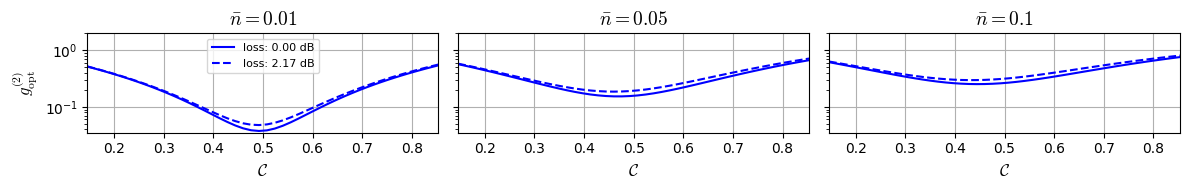

In [75]:
import matplotlib.pyplot as plt
from itertools import product

import matplotlib as mpl
mpl.rcParams['text.usetex'] = False
mpl.rcParams['mathtext.fontset'] = 'cm'

n_out_plot = [0.01, 0.05, 0.1]
gamma_plot = [0., .5]
J_plot = vec_J
U_plot = [0.01]

n_plot_x = len(n_out_plot)   # columns: n_out
n_plot_y = 1   # rows: gamma

xaxis = np.sin(J_plot) ** 2

linestyles = ['-', '--']

fig, ax = plt.subplots(n_plot_y, n_plot_x, figsize=(4 * n_plot_x, 2 * n_plot_y), sharex=True, sharey=True)

for i, gamma in enumerate(gamma_plot):       # rows

    for j, n_out in enumerate(n_out_plot):   # columns

        for U in U_plot:
            dat_theta = []
            g2_min = 100.
            for J in J_plot:
                g2 = results[(U, J, n_out, gamma)]['g2']
                n_photon = results[(U, J, n_out, gamma)]['n_photon']
                dat_theta.append(g2)
                if g2 < g2_min:
                    g2_min = g2
            #print(f"(gamma,n_out,U)=({gamma, n_out, U}), min={g2_min}")

            ax[j].semilogy(xaxis, dat_theta, "b", linestyle=linestyles[i], label=rf"loss: {np.abs(10*np.log10(np.exp(-gamma))):.2f} dB", linewidth=1.5)

        ax[j].grid(True)
        ax[j].set_xlim([np.min(xaxis), np.max(xaxis)])
        ax[j].set_ylim([0.035, 2.])

        if j == 0:
            ax[j].set_ylabel(r"$g^{(2)}_\text{opt}$", fontsize=12)

        ax[j].set_xlabel(r"$\mathcal{C}$", fontsize=12)

        # Upper titles: n_out values for each column
        ax[j].set_title(rf"$\bar{{n}}={n_out}$", fontsize=14, fontweight='bold')

    # Left titles: gamma values for each row
    # ax[0].annotate(
    #     rf"$\tilde{{\gamma}}={gamma:.1f}$",
    #     xy=(0, 0.5), xycoords='axes fraction',
    #     xytext=(-0.3, 0.5), textcoords='axes fraction',
    #     fontsize=14, ha='center', va='center', rotation=90, fontweight='bold'
    # )

ax[0].legend(fontsize=8, loc='best')

plt.tight_layout()
plt.show()

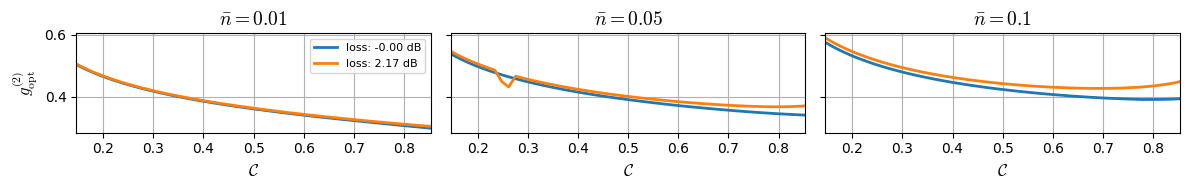

In [76]:
import matplotlib.pyplot as plt
from itertools import product

import matplotlib as mpl
mpl.rcParams['text.usetex'] = False
mpl.rcParams['mathtext.fontset'] = 'cm'

n_out_plot = [0.01, 0.05, 0.1]
gamma_plot = [0., .5]
J_plot = vec_J
U_plot = [0.1]

n_plot_x = len(n_out_plot)   # columns: n_out
n_plot_y = 1   # rows: gamma

xaxis = np.sin(J_plot) ** 2

fig, ax = plt.subplots(n_plot_y, n_plot_x, figsize=(4 * n_plot_x, 2 * n_plot_y), sharex=True, sharey=True)

for gamma in gamma_plot:       # rows

    for j, n_out in enumerate(n_out_plot):   # columns

        for U in U_plot:
            dat_theta = []
            g2_min = 100.
            for J in J_plot:
                theta = results[(U, J, n_out, gamma)]['phase']
                dat_theta.append(theta)

            #print(f"(gamma,n_out,U)=({gamma, n_out, U}), min={g2_min}")

            ax[j].plot(xaxis, dat_theta, "-", label=rf"loss: {-10*np.log10(np.exp(-gamma)):.2f} dB", linewidth=2)

        ax[j].grid(True)
        ax[j].set_xlim([np.min(xaxis), np.max(xaxis)])
        #ax[j].set_ylim([0.035, 2.])

        if j == 0:
            ax[j].set_ylabel(r"$g^{(2)}_\text{opt}$", fontsize=12)

        ax[j].set_xlabel(r"$\mathcal{C}$", fontsize=12)

        # Upper titles: n_out values for each column
        ax[j].set_title(rf"$\bar{{n}}={n_out}$", fontsize=14, fontweight='bold')

    # Left titles: gamma values for each row
    # ax[0].annotate(
    #     rf"$\tilde{{\gamma}}={gamma:.1f}$",
    #     xy=(0, 0.5), xycoords='axes fraction',
    #     xytext=(-0.3, 0.5), textcoords='axes fraction',
    #     fontsize=14, ha='center', va='center', rotation=90, fontweight='bold'
    # )

ax[0].legend(fontsize=8, loc='best')

plt.tight_layout()
plt.show()

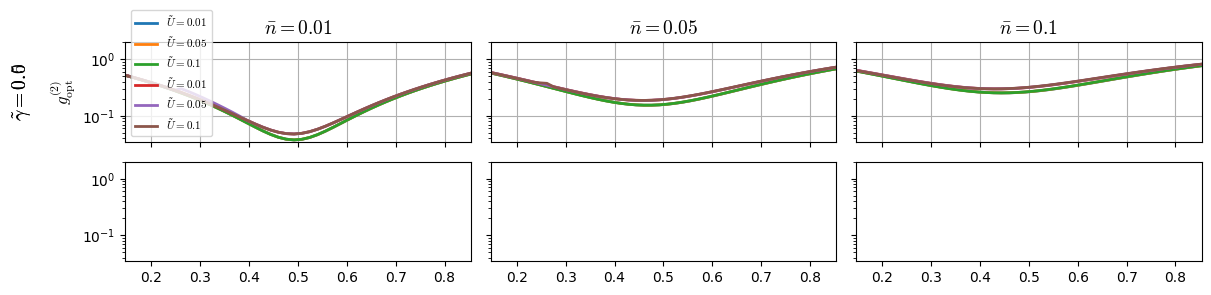

In [ ]:
import matplotlib.pyplot as plt
from itertools import product

import matplotlib as mpl
mpl.rcParams['text.usetex'] = False
mpl.rcParams['mathtext.fontset'] = 'cm'

n_out_plot = [0.01, 0.05, 0.1]
gamma_plot = [0., .5]
J_plot = vec_J
U_plot = [0.01, 0.05, 0.1]

n_plot_x = len(n_out_plot)   # columns: n_out
n_plot_y = len(gamma_plot)   # rows: gamma

xaxis = np.sin(J_plot) ** 2

fig, ax = plt.subplots(n_plot_y, n_plot_x, figsize=(4 * n_plot_x, 1.5 * n_plot_y), sharex=True, sharey=True)

for i, gamma in enumerate(gamma_plot):       # rows

    for j, n_out in enumerate(n_out_plot):   # columns

        for U in U_plot:
            dat_theta = []
            g2_min = 100.
            for J in J_plot:
                g2 = results[(U, J, n_out, gamma)]['g2']
                n_photon = results[(U, J, n_out, gamma)]['n_photon']
                dat_theta.append(g2)
                if g2 < g2_min:
                    g2_min = g2
            #print(f"(gamma,n_out,U)=({gamma, n_out, U}), min={g2_min}")

            ax[i, j].semilogy(xaxis, dat_theta, "-", label=rf"$\tilde{{U}}={U}$", linewidth=2)

        ax[i, j].grid(True)
        ax[i, j].set_xlim([np.min(xaxis), np.max(xaxis)])
        ax[i, j].set_ylim([0.035, 2.])

        if j == 0:
            ax[i, j].set_ylabel(r"$g^{(2)}_\text{opt}$", fontsize=12)

        if i == n_plot_y - 1:
            ax[i, j].set_xlabel(r"$\mathcal{C}$", fontsize=12)

        # Upper titles: n_out values for each column
        if i == 0:
            ax[i, j].set_title(rf"$\bar{{n}}={n_out}$", fontsize=14, fontweight='bold')

    # Left titles: gamma values for each row
    ax[i, 0].annotate(
        rf"$\tilde{{\gamma}}={gamma:.1f}$",
        xy=(0, 0.5), xycoords='axes fraction',
        xytext=(-0.3, 0.5), textcoords='axes fraction',
        fontsize=14, ha='center', va='center', rotation=90, fontweight='bold'
    )

ax[0, 0].legend(fontsize=8, loc='lower left')

plt.tight_layout()
plt.show()

In [7]:
U = 0.01
J = vec_J[len(vec_J) // 2]
n_out = 0.01
gamma = 0.

print(f"g2: {results[(U, J, n_out, gamma)]['g2']:.6f}")
print(f"n_photon: {results[(U, J, n_out, gamma)]['n_photon']:.6f}")
print(f"phase: {results[(U, J, n_out, gamma)]['phase']/np.pi:.6f}pi")
print(f"J: {results[(U, J, n_out, gamma)]['J']}")
0.25 * results[(U, J, n_out, gamma)]['na'] * np.abs(np.exp(1j*results[(U, J, n_out, gamma)]['phase']) + 1) ** 2

g2: 0.038517
n_photon: 3.065302
phase: 0.036563pi
J: 0.7934124303708916


np.float64(0.00996699681743259)

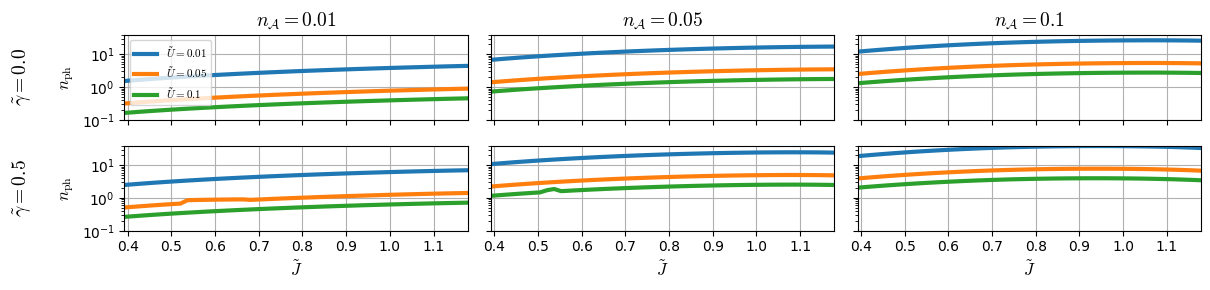

In [8]:
import matplotlib.pyplot as plt
from itertools import product

import matplotlib as mpl
mpl.rcParams['text.usetex'] = False
mpl.rcParams['mathtext.fontset'] = 'cm'

n_out_plot = [0.01, 0.05, 0.1]
gamma_plot = [0., .5]
J_plot = vec_J
U_plot = [0.01, 0.05, 0.1]

n_plot_x = len(n_out_plot)   # columns: n_out
n_plot_y = len(gamma_plot)   # rows: gamma

xaxis = J_plot

fig, ax = plt.subplots(n_plot_y, n_plot_x, figsize=(4 * n_plot_x, 1.5 * n_plot_y), sharex=True, sharey=True)

for i, gamma in enumerate(gamma_plot):       # rows
    for j, n_out in enumerate(n_out_plot):   # columns

        for U in U_plot:
            dat_n_photon = []
            for J in J_plot:
                dat_n_photon.append(results[(U, J, n_out, gamma)]['n_photon'])

            ax[i, j].semilogy(xaxis, dat_n_photon, "-", label=rf"$\tilde{{U}}={U}$", linewidth=3)

        ax[i, j].grid(True)
        ax[i, j].set_xlim([np.min(xaxis), np.max(xaxis)])
        ax[i, j].set_ylim([0.1, 40])

        if j == 0:
            ax[i, j].set_ylabel(r"$n_\text{ph}$", fontsize=12)

        if i == n_plot_y - 1:
            ax[i, j].set_xlabel(r"$\tilde{J}$", fontsize=12)

        # Upper titles: n_out values for each column
        if i == 0:
            ax[i, j].set_title(rf"$n_\mathcal{{A}}={n_out}$", fontsize=14, fontweight='bold')

    # Left titles: gamma values for each row
    ax[i, 0].annotate(
        rf"$\tilde{{\gamma}}={gamma:.1f}$",
        xy=(0, 0.5), xycoords='axes fraction',
        xytext=(-0.3, 0.5), textcoords='axes fraction',
        fontsize=14, ha='center', va='center', rotation=90, fontweight='bold'
    )

ax[0, 0].legend(fontsize=8, loc='best')

plt.tight_layout()
plt.show()

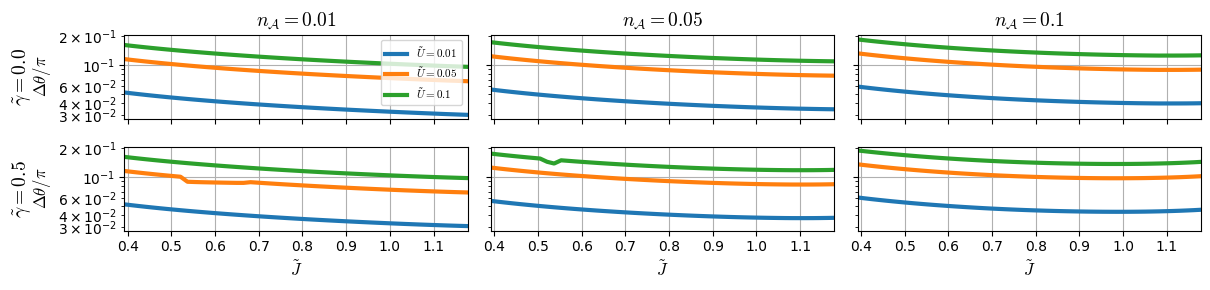

In [9]:
import matplotlib.pyplot as plt
from itertools import product

import matplotlib as mpl
mpl.rcParams['text.usetex'] = False
mpl.rcParams['mathtext.fontset'] = 'cm'

n_out_plot = [0.01, 0.05, 0.1]
gamma_plot = [0., .5]
J_plot = vec_J
U_plot = [0.01, 0.05, 0.1]

n_plot_x = len(n_out_plot)   # columns: n_out
n_plot_y = len(gamma_plot)   # rows: gamma

xaxis = J_plot

fig, ax = plt.subplots(n_plot_y, n_plot_x, figsize=(4 * n_plot_x, 1.5 * n_plot_y), sharex=True, sharey=True)

for i, gamma in enumerate(gamma_plot):       # rows
    for j, n_out in enumerate(n_out_plot):   # columns

        for U in U_plot:
            dat_theta = []
            for J in J_plot:
                dat_theta.append(results[(U, J, n_out, gamma)]['phase'])

            dat_theta = np.array(dat_theta)
            ax[i, j].semilogy(xaxis, dat_theta / np.pi, "-", label=rf"$\tilde{{U}}={U}$", linewidth=3)

        ax[i, j].grid(True)
        ax[i, j].set_xlim([np.min(xaxis), np.max(xaxis)])
        #
        #ax[i, j].set_ylim([0.1, 1.])

        if j == 0:
            ax[i, j].set_ylabel(r"$\Delta \theta/\pi$", fontsize=12)

        if i == n_plot_y - 1:
            ax[i, j].set_xlabel(r"$\tilde{J}$", fontsize=12)

        # Upper titles: n_out values for each column
        if i == 0:
            ax[i, j].set_title(rf"$n_\mathcal{{A}}={n_out}$", fontsize=14, fontweight='bold')

    # Left titles: gamma values for each row
    ax[i, 0].annotate(
        rf"$\tilde{{\gamma}}={gamma:.1f}$",
        xy=(0, 0.5), xycoords='axes fraction',
        xytext=(-0.3, 0.5), textcoords='axes fraction',
        fontsize=14, ha='center', va='center', rotation=90, fontweight='bold'
    )

ax[0, 0].legend(fontsize=8, loc='best')

plt.tight_layout()
plt.show()

In [5]:
import matplotlib.pyplot as plt
from itertools import product

import matplotlib as mpl
mpl.rcParams['text.usetex'] = False
mpl.rcParams['mathtext.fontset'] = 'cm'

n_out_plot = [0.01, 0.05, 0.1]
gamma_plot = gammas[:-1]
n_photon_plot = vec_n_photon
U_plot = [0.01, 0.05]

n_plot_x = len(gamma_plot)
n_plot_y = len(n_out_plot)

xaxis = n_photon_plot

fig, ax = plt.subplots(n_plot_y, n_plot_x, figsize=(4 * n_plot_x, 1.5 * n_plot_y), sharex=True, sharey=True)

for i, n_out in enumerate(n_out_plot):
    for j, gamma in enumerate(gamma_plot):

        for U in U_plot:
            dat_theta = []
            for n_photon in n_photon_plot:
                dat_theta.append(results[(U, n_photon, n_out, gamma)]['g2'])

            ax[i, j].loglog(xaxis, dat_theta, "-", label=rf"$\tilde{{U}}={U}$", linewidth=3)

        ax[i, j].grid(True)
        ax[i, j].set_xlim([np.min(xaxis), np.max(xaxis)])
        ax[i, j].set_ylim([0.035, 2.])

        if j == 0:
            ax[i, j].set_ylabel(r"$g^{(2)}_\text{opt}$")

        if i == n_plot_y - 1:
            ax[i, j].set_xlabel(r"$n_S$")

        # Upper titles: gamma values for each column
        if i == 0:
            ax[i, j].set_title(rf"$\tilde{{\gamma}}={gamma:.1f}$", fontsize=11,fontweight='bold')

    # Left titles: n_out values for each row, rotated 90 degrees
    ax[i, 0].annotate(
        rf"$n_A={n_out}$",
        xy=(0, 0.5), xycoords='axes fraction',
        xytext=(-0.3, 0.5), textcoords='axes fraction',
        fontsize=11, ha='center', va='center', rotation=90, fontweight='bold'
    )

ax[0, 0].legend(fontsize=6, loc='lower right')

#fig.tight_layout()
plt.show()

NameError: name 'vec_n_photon' is not defined

 (n,gamma): (0.01, 0.0)
 (n,gamma): (0.01, 0.1)
 (n,gamma): (0.05, 0.0)
 (n,gamma): (0.05, 0.1)
 (n,gamma): (0.1, 0.0)
 (n,gamma): (0.1, 0.1)


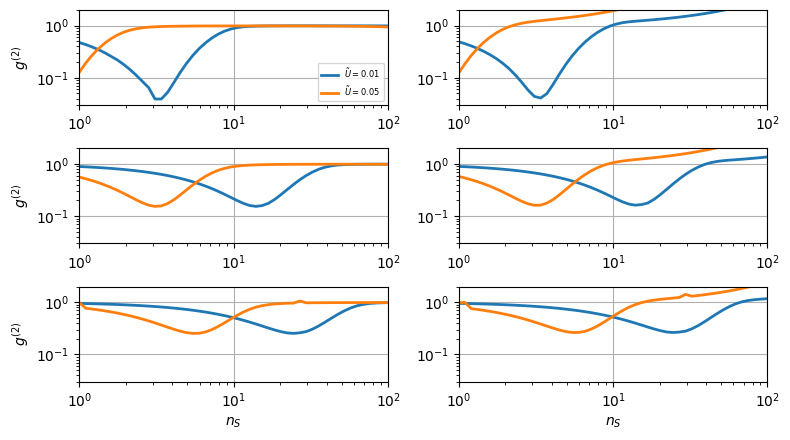

In [ ]:
import matplotlib.pyplot as plt
from itertools import product

n_out_plot = [0.01, 0.05, 0.1]
gamma_plot = gammas[:-1]
n_photon_plot = vec_n_photon
U_plot = [0.01, 0.05]

n_plot_x = len(gamma_plot)
n_plot_y = len(n_out_plot)

xaxis = n_photon_plot

fig, ax = plt.subplots(n_plot_y, n_plot_x, figsize=(4 * n_plot_x, 1.5 * n_plot_y))

for i, n_out in enumerate(n_out_plot):
    for j, gamma in enumerate(gamma_plot):

        print(f" (n,gamma): {(n_out, gamma)}")
        for U in U_plot:
            dat_theta = []
            for n_photon in n_photon_plot:
                dat_theta.append(results[(U, n_photon, n_out, gamma)]['g2'])

            ax[i,j].loglog(xaxis, dat_theta, "-", label=rf"$\tilde{{U}}={U}$", linewidth=2)

            ax[i,j].grid(True)
            ax[i,j].set_xlim([np.min(xaxis), np.max(xaxis)])
            ax[i,j].set_ylim([0.03, 2.])

            if j == 0:
                ax[i,j].set_ylabel(r"$g^{(2)}$")
            
            if i == n_plot_y - 1:
                ax[i,j].set_xlabel(r"$n_S$")

    
    ax[0,0].legend(fontsize=6, loc='lower right')

    plt.tight_layout()

 (n,gamma): (0.01, 0.0)
 (n,gamma): (0.01, 0.1)
 (n,gamma): (0.05, 0.0)
 (n,gamma): (0.05, 0.1)
 (n,gamma): (0.1, 0.0)
 (n,gamma): (0.1, 0.1)


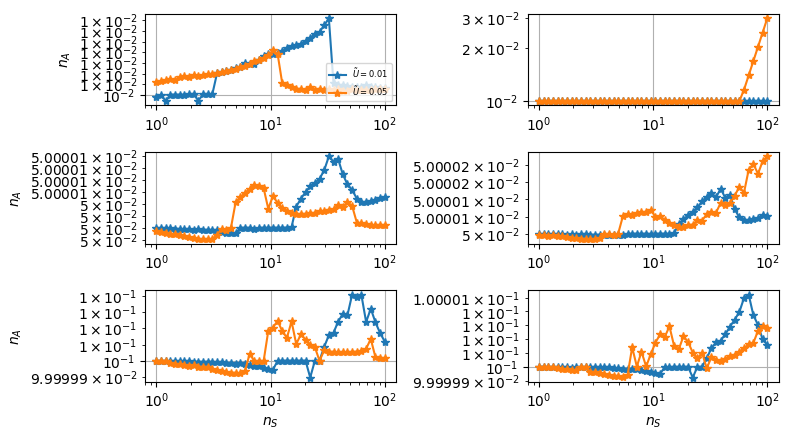

In [16]:
import matplotlib.pyplot as plt
from itertools import product

n_out_plot = [0.01, 0.05, 0.1]
gamma_plot = gammas[:-1]
n_photon_plot = vec_n_photon
U_plot = [0.01, 0.05]

n_plot_x = len(gamma_plot)
n_plot_y = len(n_out_plot)

xaxis = n_photon_plot

fig, ax = plt.subplots(n_plot_y, n_plot_x, figsize=(4 * n_plot_x, 1.5 * n_plot_y))

for i, n_out in enumerate(n_out_plot):
    for j, gamma in enumerate(gamma_plot):

        print(f" (n,gamma): {(n_out, gamma)}")
        for U in U_plot:
            dat_n = []
            for n_photon in n_photon_plot:
                dat_n.append(results[(U, n_photon, n_out, gamma)]['na'])

            ax[i,j].loglog(xaxis, dat_n, "*-", label=rf"$\tilde{{U}}={U}$")

            ax[i,j].grid(True)
            # ax[i,j].set_xlim([np.min(xaxis), np.max(xaxis)])
            # ax[i,j].set_ylim([0.03, 10.])

            if j == 0:
                ax[i,j].set_ylabel(r"$n_A$")
            
            if i == n_plot_y - 1:
                ax[i,j].set_xlabel(r"$n_S$")

    
    ax[0,0].legend(fontsize=6, loc='lower right')

    plt.tight_layout()

# Dependence nonlinearity

# analyze resilience

In [3]:
from scipy.integrate import solve_ivp

def get_g2(alpha, N, M):
    n_alpha = np.abs(alpha) ** 2

    numerator = (
        n_alpha ** 2
        + 4 * N * n_alpha
        + M * alpha.conj() ** 2
        + M.conj() * alpha ** 2
        + 2 * N ** 2
        + M * M.conj()
    )
    denominator = n_alpha ** 2 + 2 * N * n_alpha + N ** 2
    g2 = numerator / denominator

    return g2.real

def solve_ODE_AS_mode(
    J, 
    U_ns, 
    alpha_0, 
    tlist, 
    Delta=0.,
    gamma=0.
    ):

  def dF(t, v):

    # extract alpha, N, M from vector
    alpha, N, M = v[0], v[1], v[2]

    # compute differentials
    d_alpha = (-gamma/2. - 1j*Delta) * alpha \
        -2j * J * alpha - 1j * 0.5 * U_ns * alpha - 1j * 0.5 * U_ns * alpha.conj()
    d_N = -gamma * N - U_ns * M.imag
    d_M = (-gamma - 2j*Delta) * M \
        -4j * J * M - 1j * U_ns * M - 1j * U_ns * (N + 0.5)

    # return differentials in array format
    return np.array([d_alpha, d_N, d_M])

  # solve the system, with right initial state
  y0 = np.array([alpha_0, 0, 0])
  sol = solve_ivp(dF, [tlist[0], tlist[-1]], y0=y0, t_eval=tlist)

  # return alpha, N, M tuple
  return sol.y[0], sol.y[1], sol.y[2]

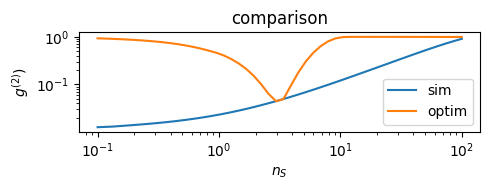

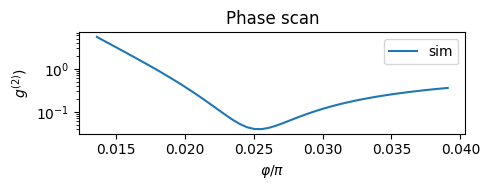

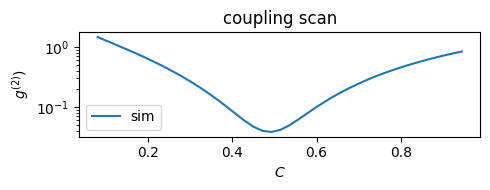

In [4]:


U = 0.01
n_out_tar = 0.01
gamma = 0.

vec_g2 = [results[(U, ns, n_out_tar, gamma)]['g2'] for ns in vec_ns]
ind = np.argmin(vec_g2)
g2_min = np.min(vec_g2)
ns_min = float(vec_ns[ind])
res = results[(U, ns_min, n_out_tar, gamma)]
phase_min = res['phase']
coupling_min = res['coupling']

phase_scan = np.linspace(-0.04, 0.04, 50)
coupling_scan = np.linspace(-np.pi/6, np.pi/6)

# comparison with optimization

plt.figure(figsize=(5,2))
vec_g2_sim = []
for ns in vec_ns:
    alpha_0 = 1j * res['phase'] * np.sqrt(ns) / np.sqrt(2)
    alpha, N, M = solve_ODE_AS_mode(J=res['coupling'], U_ns=U * ns, alpha_0=alpha_0, tlist=[0.,1.], gamma=gamma)

    g2 = get_g2(alpha[-1], N[-1], M[-1])
    vec_g2_sim.append(g2)

plt.loglog(vec_ns, vec_g2_sim, label='sim')
plt.loglog(vec_ns, vec_g2, label='optim')

plt.legend()
plt.xlabel(r"$n_S$")
plt.ylabel(r"$g^{(2)})$")
plt.title('comparison')
plt.tight_layout()
plt.show()

# phase scan

plt.figure(figsize=(5,2))
vec_g2_phase = []
for phase in phase_scan:
    alpha_0 = 1j * (phase + phase_min) * np.sqrt(ns_min) / np.sqrt(2)
    alpha, N, M = solve_ODE_AS_mode(J=res['coupling'], U_ns=U * ns_min, alpha_0=alpha_0, tlist=[0.,1.], gamma=gamma)

    g2 = get_g2(alpha[-1], N[-1], M[-1])
    vec_g2_phase.append(g2)

plt.semilogy((phase_scan + phase_min)/np.pi, vec_g2_phase, label='sim')
plt.legend()
plt.xlabel(r"$\varphi/\pi$")
plt.ylabel(r"$g^{(2)})$")
plt.title('Phase scan')
plt.tight_layout()
plt.show()

# scan coupling
plt.figure(figsize=(5,2))
vec_g2_coupling = []
for coupling in coupling_scan:
    alpha_0 = 1j * phase_min* np.sqrt(ns_min) / np.sqrt(2)
    alpha, N, M = solve_ODE_AS_mode(J=coupling + coupling_min, U_ns=U * ns_min, alpha_0=alpha_0, tlist=[0.,1.], gamma=gamma)

    g2 = get_g2(alpha[-1], N[-1], M[-1])
    vec_g2_coupling.append(g2)

plt.semilogy(np.sin(coupling_scan + coupling_min) ** 2, vec_g2_coupling, label='sim')
plt.legend()
plt.xlabel(r"$C$")
plt.ylabel(r"$g^{(2)})$")
plt.title('coupling scan')
plt.tight_layout()
plt.show()

# AS occupation check

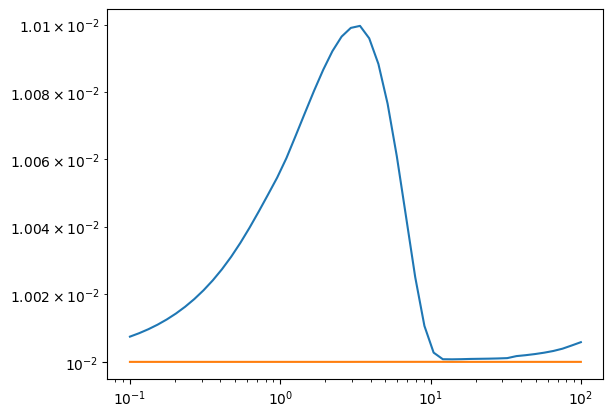

In [5]:
U = 0.01
n_out_tar = 0.01
gamma = 0.

vec_phase = np.array([results[(U, ns, n_out_tar, gamma)]['phase'] for ns in vec_ns])
vec_alpha = np.array([results[(U, ns, n_out_tar, gamma)]['alpha'] for ns in vec_ns])
vec_N = np.array([results[(U, ns, n_out_tar, gamma)]['N'] for ns in vec_ns])

na_phase = 0.5 * vec_phase ** 2 * vec_ns
na_meas = np.abs(vec_alpha) ** 2 + vec_N

plt.loglog(vec_ns, na_phase)
# plt.semilogy(vec_ns, vec_ns)
plt.loglog(vec_ns, na_meas)

In [ ]:
np.argmax(vec_phase)

np.int64(0)

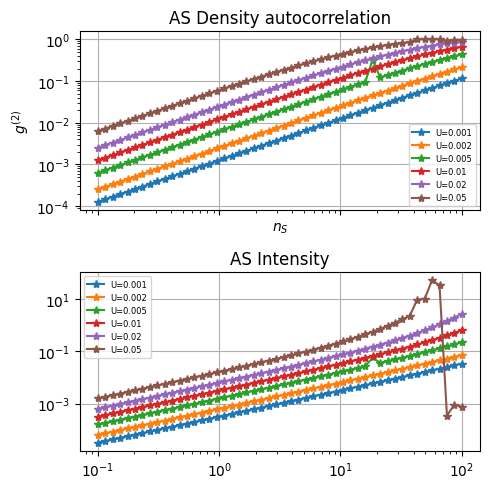

<Figure size 500x200 with 0 Axes>

In [ ]:
import matplotlib.pyplot as plt

n_out_tar = None
gamma = 0.

fig, ax = plt.subplots(2,1, figsize=(5,5), sharex=True)
for U in vec_U[:-1]:
    dat_theta = []
    for ns in vec_ns:
        dat_theta.append(results[(U, ns, n_out_tar, gamma)]['g2'])

    ax[0].loglog(vec_ns, dat_theta, "*-", label=f"U={U}")

#plt.ylim(0,0.3)
ax[0].grid(True)
ax[0].legend(fontsize=6)
ax[0].set_title("AS Density autocorrelation")
ax[0].set_ylabel(r"$g^{(2)}$")

plt.figure(figsize=(5,2))
for U in vec_U[:-1]:
    dat_n_out = []
    for ns in vec_ns:
        n_out = np.abs(results[(U, ns, n_out_tar, gamma)]['alpha']) ** 2 \
            + np.abs(results[(U, ns, n_out_tar, gamma)]['N'])
        dat_n_out.append(n_out)

    ax[1].loglog(vec_ns, dat_n_out, "*-", label=f"U={U}")

ax[1].grid(True)
ax[1].legend(fontsize=6)
ax[0].set_xlabel(r"$n_S$")
ax[1].set_title("AS Intensity")

fig.tight_layout()

In [ ]:
results[(vec_U[0],vec_ns[0])]['g2']

np.complex128(0.19651278031228242+0j)